In [1]:
import numpy as np
import pandas as pd
import os, shutil
from tqdm import tqdm
import re
import matplotlib.pyplot as plt
from math import factorial

In [2]:
RESULTS_PREFIX = 'results'
HP_RESULTS_PREFIX = 'hpSearch'

In [3]:
input_dir = "/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns"
sweep_names = [
    "PACS_resnet18-BN_ERM_0", "PACS_resnet50-BN_ERM_0",
    "VLCS_resnet18-BN_ERM_0", "VLCS_resnet50-BN_ERM_0",
    "TerraIncognita_resnet18-BN_ERM_0", "TerraIncognita_resnet50-BN_ERM_0",
    "OfficeHome_resnet18-BN_ERM_0", "OfficeHome_resnet50-BN_ERM_0"
]

In [4]:
def camel_case_split(identifier):
    matches = re.finditer('.+?(?:(?<=[a-z])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])|$)', identifier)
    return [m.group(0) for m in matches]

def get_test_env(args):
    test_envs = args['test_envs']
    assert len(test_envs) == 1
    test_env = test_envs[0]
    return test_env

def get_names(df_res, test_env):
    train_out_names = [col for col in df_res.columns
                            if 'env' in col and
                                'out_acc' in col and
                                str(test_env) not in col]
    test_out_names = [col for col in df_res.columns
                            if 'env' in col and
                                'out_acc' in col and
                                str(test_env) in col]
    test_in_names = [col for col in df_res.columns
                            if 'env' in col and
                                'in_acc' in col and
                                str(test_env) in col]
    assert len(test_out_names) == 1
    assert len(test_in_names) == 1
    test_out_name = test_out_names[0]
    test_in_name = test_in_names[0]
    return train_out_names, test_out_name, test_in_name

def fill_nans(acc_dict, test_in_name, adapt_algorithm, loc_alg_name):
    # Extract loc algo setting names
    find_algo, fix_algo, granularity = camel_case_split(loc_alg_name)

    # Append algo names to dictionary
    acc_dict['adapt_algorithm'].append(adapt_algorithm)
    acc_dict['find_algo'].append(find_algo)
    acc_dict['fix_algo'].append(fix_algo)
    acc_dict['granularity'].append(granularity)

    # Append target acc to dictionary
    acc_dict[test_in_name].append(np.nan)

def fill_dg(iid_dict, orc_dict, man_dict, df, train_out_names, test_out_name, test_in_name, args):
    # Get best train and test out idx
    df['train_out_mean'] = df[train_out_names].mean(axis=1)
    best_train_out_idx = df['train_out_mean'].idxmax()
    best_test_out_idx = df[test_out_name].idxmax()

    # Get best train and test out based test-in acc
    iidacc = df[test_in_name].iloc[best_train_out_idx]
    orcacc = df[test_in_name].iloc[best_test_out_idx]

    # TODO: Assumes that DG is encountered 1st, fix it!
    # Append acc to both dictionaries
    iid_dict[test_in_name] = [iidacc]
    orc_dict[test_in_name] = [orcacc]
    man_dict[test_in_name] = []
    
    # Append algo names to both dictionaries
    iid_dict['adapt_algorithm'] = ['DG']
    iid_dict['find_algo'] = ['DG']
    iid_dict['fix_algo'] = ['DG']
    iid_dict['granularity'] = ['DG']
    orc_dict['adapt_algorithm'] = ['DG']
    orc_dict['find_algo'] = ['DG']
    orc_dict['fix_algo'] = ['DG']
    orc_dict['granularity'] = ['DG']
    man_dict['adapt_algorithm'] = []
    man_dict['find_algo'] = []
    man_dict['fix_algo'] = []
    man_dict['granularity'] = []

    # Append seed to both dictionaries
    # iid_dict['hparams_seed'].append(args['hparams_seed'])
    # iid_dict['seed'].append(args['seed'])
    # iid_dict['trial_seed'].append(args['trial_seed'])
    # orc_dict['hparams_seed'].append(args['hparams_seed'])
    # orc_dict['seed'].append(args['seed'])
    # orc_dict['trial_seed'].append(args['trial_seed'])

def fill_row_loc(acc_dict, row, test_in_name, args):
    # Append algo names to dictionary
    acc_dict['adapt_algorithm'].append(args['adapt_algorithm'])
    if 'find_algo' in row: 
        # for loc TTA
        acc_dict['find_algo'].append(args['find_algo'])
        acc_dict['fix_algo'].append(args['fix_algo'])
        acc_dict['granularity'].append(args['granularity'])
    else:
        # for full TTA
        acc_dict['find_algo'].append('None')
        acc_dict['fix_algo'].append('None')
        acc_dict['granularity'].append('None')

    # Append target acc to dictionary
    acc_dict[test_in_name].append(row[test_in_name])

def fill_meta_data(acc_dict, test_in_name, dataset, backbone, dg_name, mark, hp_mode):
    acc_dict['hp_mode'] = [hp_mode for _ in range(len(acc_dict[test_in_name]))]
    acc_dict['dataset'] = [dataset for _ in range(len(acc_dict[test_in_name]))]
    acc_dict['backbone'] = [backbone for _ in range(len(acc_dict[test_in_name]))]
    acc_dict['dg'] = [dg_name for _ in range(len(acc_dict[test_in_name]))]
    acc_dict['mark'] = [mark for _ in range(len(acc_dict[test_in_name]))]

def get_df(acc_dict):
    # Create dataframe from dictionary
    df = pd.DataFrame.from_dict(acc_dict)

    # Compute average accuracy
    df['Avg'] = df[[col for col in df.columns
                            if 'in_acc' in col]].mean(axis=1)

    # Sort dataframe columns
    df = df[['adapt_algorithm', 'granularity', 'find_algo', 'fix_algo',
                     'env0_in_acc', 'env1_in_acc', 'env2_in_acc', 'env3_in_acc', 'Avg',
                     'hp_mode', 'dataset', 'backbone', 'dg', 'mark']]
    
    return df

def fill_meta_data_df(df, target_col, mark, dataset, test_env, low_data_frac, backbone, dg, tta_name, hp_mode):
    # Store accs
    df['tta_acc'] = df[target_col]

    # Drop columns containing 'step'
    df.drop(columns=[col for col in df.columns if 'env' in col], inplace=True)

    # Store other params
    df['mark'] = mark
    df['dataset'] = dataset
    df['test_env'] = test_env
    df['data_frac'] = int(low_data_frac*100)
    df['backbone'] = backbone
    df['dg'] = dg
    df['tta'] = tta_name
    df['hp_mode'] = hp_mode

    return df

def calculate_shapley_values(powerset):
    """
    Calculate Shapley values of players in a cooperative game.
    
    The Shapley value is a solution concept in cooperative game theory that assigns a payout to 
    each player in the game, proportional to their marginal contribution to the total payout.

    Parameters:
    powerset (dict): a dictionary with keys as tuples representing subsets of players and 
    values as their corresponding game values.

    Returns:
    dict: a dictionary with players as keys and their corresponding Shapley values as values.
    """

    # Ensure the input is a dictionary and keys are tuples
    assert isinstance(powerset, dict), "Input should be a dictionary"
    assert all(isinstance(i, tuple) for i in powerset.keys()), "Keys should be tuples"

    # Flatten the list of subsets to find all unique players
    players = set(player for subset in powerset.keys() for player in subset)
    total_players = len(players)  # total number of players

    # Initialize the Shapley values with 0 for all players
    shapley_values = {player: 0 for player in players}

    # Iterate over each subset in the power set
    for subset, subset_value in powerset.items():
        players_in_subset = len(subset)  # number of players in the subset

        # Iterate over each player in the subset
        for player in subset:
            # Create the subset without the current player
            subset_excluding_player = tuple([p for p in subset if p != player])
            # Get the value for the subset without the player or 0 if it doesn't exist
            value_of_excluded_subset = powerset.get(subset_excluding_player, 0)
            
            # Calculate the player's marginal contribution
            marginal_contribution = subset_value - value_of_excluded_subset
                
            # Compute the Shapley value for the player
            weight = factorial(players_in_subset - 1) * factorial(total_players - players_in_subset) / factorial(total_players)
            shapley_values[player] += marginal_contribution * weight

    return shapley_values

# powerset = {
#     (): 0,
#     ('A',): 1,
#     ('B',): 2,
#     ('C',): 3,
#     ('A', 'B'): 4,
#     ('A', 'C'): 5,
#     ('B', 'C'): 7,
#     ('A', 'B', 'C'): 10
# }

def get_kp_values(df, all_box_list, target_col):
    # Store accs
    df['tta_acc'] = df[target_col]

    #########################################
    # Get correlation and shapley values code
    #########################################

    # Get dataframe with only relevant columns
    df_inq = df[['find_algo'] + all_box_list + ['tta_acc']]

    # Compute pearson correlation values
    corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
    corr_values = dict(sorted(corr_values.items(), key=lambda x: x))
    corr_values['classifier'] = corr_values.pop('classifier')

    # Compute shapley values
    powerset_dict = {tuple(row['find_algo'].split('_')) : row['tta_acc'] for idx, row in df_inq.iterrows()}
    powerset_dict[()] = powerset_dict.pop(tuple(['none']))
    shapley_values = calculate_shapley_values(powerset_dict)
    shapley_values = dict(sorted(shapley_values.items(), key=lambda x: x))
    shapley_values['classifier'] = shapley_values.pop('classifier')

    # Add to df
    df_corr = pd.DataFrame.from_dict(corr_values, orient='index').rename(columns={0: 'corr'})
    df_shap = pd.DataFrame.from_dict(shapley_values, orient='index').rename(columns={0: 'shap'})


    ############################
    # Get max weight code
    ############################
    # Get dataframe with only relevant columns
    df_inq = df[['find_algo', 'count'] + all_box_list + ['tta_acc']]

    # Compute greedy shapley values
    full_name = ''
    greedy_rank = ['none']
    for layer_name in df_shap.sort_values(by='shap', ascending=False).index:
        if full_name != '':
            full_name += '_'
        full_name += layer_name
        greedy_rank.append(full_name)
    greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

    # Add greedy shapley values to grouped data
    greedy_shap_values = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

    # Compute greedy correlation values
    full_name = ''
    greedy_rank = ['none']
    for layer_name in df_corr.sort_values(by='corr', ascending=False).index:
        if full_name != '':
            full_name += '_'
        full_name += layer_name
        greedy_rank.append(full_name)
    greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

    # Add greedy correlation values to grouped data
    greedy_corr_values = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

    # Compute greedy best single values
    full_name = ''
    greedy_rank = ['none']
    for layer_name in df_inq[df_inq['count'] == 1].sort_values(by='tta_acc', ascending=False)['find_algo'].values:
        if full_name != '':
            full_name += '_'
        full_name += layer_name
        greedy_rank.append(full_name)
    greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

    ############################
    # Add greedy best single values to grouped data
    greedy_sing_values = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

    # Get best shapley, correlation and single values
    best_shapBinary_GreedyKP = max(greedy_shap_values)
    best_corrBinary_GreedyKP = max(greedy_corr_values)
    best_singBinary_GreedyKP = max(greedy_sing_values)

    return best_shapBinary_GreedyKP, best_corrBinary_GreedyKP, best_singBinary_GreedyKP

def get_label_values(df, all_box_list, target_col):
    # Store accs
    df['tta_acc'] = df[target_col]

    # Get dataframe with only relevant columns
    df_inq = df[['find_algo'] + all_box_list + ['tta_acc']]

    # Compute pearson correlation values
    corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
    corr_values = dict(sorted(corr_values.items(), key=lambda x: x))
    corr_values['classifier'] = corr_values.pop('classifier')

    # Compute shapley values
    powerset_dict = {tuple(row['find_algo'].split('_')) : row['tta_acc'] for idx, row in df_inq.iterrows()}
    powerset_dict[()] = powerset_dict.pop(tuple(['none']))
    shapley_values = calculate_shapley_values(powerset_dict)
    shapley_values = dict(sorted(shapley_values.items(), key=lambda x: x))
    shapley_values['classifier'] = shapley_values.pop('classifier')

    # Add to df
    df_corr = pd.DataFrame.from_dict(corr_values, orient='index').rename(columns={0: 'corr'})
    df_shap = pd.DataFrame.from_dict(shapley_values, orient='index').rename(columns={0: 'shap'})

    return df_shap, df_corr

In [5]:
sweep_name = sweep_names[0]
print(sweep_name)
print(sweep_names)
print(len(sweep_names))

PACS_resnet18-BN_ERM_0
['PACS_resnet18-BN_ERM_0', 'PACS_resnet50-BN_ERM_0', 'VLCS_resnet18-BN_ERM_0', 'VLCS_resnet50-BN_ERM_0', 'TerraIncognita_resnet18-BN_ERM_0', 'TerraIncognita_resnet50-BN_ERM_0', 'OfficeHome_resnet18-BN_ERM_0', 'OfficeHome_resnet50-BN_ERM_0']
8


In [6]:
# Get sweep dir
sweep_dir = os.path.join(input_dir, sweep_name)

# Get runs
runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

# Get unique list of all results fnames
res_fnames = sorted(list(set([fname for run in runs
                                        for fname in os.listdir(os.path.join(sweep_dir, run))
                                            if RESULTS_PREFIX in fname and\
                                                'hp' not in fname and\
                                                '.jsonl' in fname])))

# Get unique list of all hp results fnames
man_fnames = sorted(list(set([fname for run in runs
                                        for fname in os.listdir(os.path.join(sweep_dir, run))
                                            if HP_RESULTS_PREFIX in fname and\
                                                'Man' in fname and\
                                                '.jsonl' in fname])))
iid_fnames = sorted(list(set([fname for run in runs
                                        for fname in os.listdir(os.path.join(sweep_dir, run))
                                            if HP_RESULTS_PREFIX in fname and\
                                                'Iid' in fname and\
                                                '.jsonl' in fname])))
orc_fnames = sorted(list(set([fname for run in runs
                                        for fname in os.listdir(os.path.join(sweep_dir, run))
                                            if HP_RESULTS_PREFIX in fname and\
                                                'Orc' in fname and\
                                                '.jsonl' in fname])))
res_fnames, man_fnames

(['results_PseudoLabel_BestmultiTrainsubsetBlock.jsonl',
  'results_SHOT_BestmultiTrainsubsetBlock.jsonl',
  'results_TentFull_BestmultiTrainsubsetBlock.jsonl'],
 ['hpSearch_PseudoLabel_BestmultiTrainsubsetBlock_Man.jsonl',
  'hpSearch_SHOT_BestmultiTrainsubsetBlock_Man.jsonl',
  'hpSearch_TentFull_BestmultiTrainsubsetBlock_Man.jsonl'])

# Save shapley values as meta labels

In [7]:
# For different datasets and backbones
sweep_start_idx = 0
sweep_end_idx = 8

# For different TTAs
man_start_idx = 0
man_end_idx = 2

# For different envs per dataset and backbone
run_start_idx = 0
run_end_idx = 4

In [8]:
# Fixed params
full_data_col = 'hp_acc'
low_data_fracs = [0, 0.25, 0.5, 0.75, 1.0]
res_tables, all_hp_tables, best_hp_tables = {}, {}, {}

# For different datasets and backbones
for sweep_name in sweep_names[sweep_start_idx:sweep_end_idx]:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for res_fname, man_fname in zip(res_fnames[man_start_idx:man_end_idx], man_fnames[man_start_idx:man_end_idx]):
        tta_name = man_fname[:-6].split('_')[1]
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs[run_start_idx:run_end_idx]:
            run_dir = os.path.join(sweep_dir, run)

            # Read in results
            df_res = pd.read_json(os.path.join(run_dir, res_fname), lines=True)
            # Get args
            args = df_res['args'][0]
            # Get test env
            test_env = get_test_env(args)
            print('\t\ttest_env: {}'.format(test_env))

            # Read in Man results
            df_man = pd.read_json(os.path.join(run_dir, man_fname), lines=True)

            # Add dataframe to all hp tables
            all_table_name = '{}_{}:{}_{}_{}_{}'.format(mark, dataset, test_env, backbone, dg, tta_name)
            res_tables[all_table_name] = df_res
            # all_hp_tables[all_table_name] = df_man

            # Get low data cols
            low_data_cols = [col for col in df_man.columns.values if 'step' in col]
            low_data_cols = ['hp_acc']
            low_data_fracs = [1.0]

            # For different low data setups
            for target_col, low_data_frac in zip(low_data_cols, low_data_fracs):
                # get best rows for each find_algo column
                print('\t\t\ttarget_col: {}'.format(target_col))
                df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')

                # Compute few stats
                full_box_name = max(df_man_best['find_algo'], key=len)
                all_box_list = full_box_name.split('_')
                single_box_flag = np.array([False]*df_man_best.shape[0])
                train_count_arr = np.zeros(df_man_best.shape[0])
                for box in all_box_list:
                    single_box_flag = single_box_flag | (df_man_best['find_algo'] == box).values
                    df_man_best[box] = [box in row['find_algo'] for idx, row in df_man_best.iterrows()]
                    train_count_arr += df_man_best[box].astype(int).values
                df_man_best['count'] = train_count_arr.astype(int)

                only_box_list = all_box_list[1:-1]
                train_frac_arr = np.zeros(df_man_best.shape[0])
                for box in only_box_list:
                    train_frac_arr += df_man_best[box].astype(int).values
                df_man_best['train_frac'] = train_frac_arr.astype(int) / 4.0

                # get accs different loc TTA
                dg_acc = df_man_best[df_man_best['find_algo'] == 'none'][target_col].values[0]
                full_acc = df_man_best[df_man_best['find_algo'] == full_box_name][target_col].values[0]
                best_powerset_acc = df_man_best[target_col].values[0]
                worst_powerset_acc = df_man_best[target_col].values[-1]
                best_single_acc = df_man_best[single_box_flag][target_col].values[0]
                df_man_best['loc>full'] = df_man_best[target_col] - full_acc
                df_man_best['subset_quality'] = df_man_best[target_col] - df_man_best[target_col].iloc[-1]

                # get df_shap and df_corr
                df_shap, df_corr = get_label_values(df_man_best, all_box_list, target_col)

                # Merge
                df_corr_shap = pd.merge(df_corr, df_shap, left_index=True, right_index=True)

                # Save
                label_path = os.path.join(sweep_dir, run, tta_name)
                if os.path.exists(label_path):
                    shutil.rmtree(label_path)
                os.makedirs(label_path)
                df_corr_shap.to_csv(os.path.join(label_path, 'corr_shap.csv'))

                # Read
                # df_corr_shap = pd.read_csv('corr_shap.csv', index_col=0)

dataset: PACS, backbone: resnet18-BN
	tta: PseudoLabel
		test_env: 1
			target_col: hp_acc
		test_env: 2
			target_col: hp_acc


/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


		test_env: 0
			target_col: hp_acc
		test_env: 3
			target_col: hp_acc
	tta: SHOT
		test_env: 1


/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


			target_col: hp_acc
		test_env: 2
			target_col: hp_acc
		test_env: 0
			target_col: hp_acc


...

/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


		test_env: 0
			target_col: hp_acc
	tta: SHOT
		test_env: 1
			target_col: hp_acc
		test_env: 2
			target_col: hp_acc


/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


		test_env: 3
			target_col: hp_acc
		test_env: 0
			target_col: hp_acc


/tmp/ipykernel_1471522/757461356.py:285: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


In [9]:
label_path

'/home-local2/sasah14.extra.nobkp/scratch/out/stta/sweep/bestmultiruns/OfficeHome_resnet50-BN_ERM_0/fd6bc3e808e9b46f91e5ed6e2c9bcfb7/SHOT'

# Save large csvs

In [ ]:
# For different datasets and backbones
sweep_start_idx = 0
sweep_end_idx = 1

# For different TTAs
man_start_idx = 0
man_end_idx = 1

# For different envs per dataset and backbone
run_start_idx = 0
run_end_idx = 1

In [ ]:
# Fixed params
full_data_col = 'hp_acc'
low_data_fracs = [0, 0.25, 0.5, 0.75, 1.0]
res_tables, all_hp_tables, best_hp_tables = {}, {}, {}

# For different datasets and backbones
for sweep_name in sweep_names[sweep_start_idx:sweep_end_idx]:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for res_fname, man_fname in zip(res_fnames[man_start_idx:man_end_idx], man_fnames[man_start_idx:man_end_idx]):
        tta_name = man_fname[:-6].split('_')[1]
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs[run_start_idx:run_end_idx]:
            run_dir = os.path.join(sweep_dir, run)

            # Read in results
            df_res = pd.read_json(os.path.join(run_dir, res_fname), lines=True)
            # Get args
            args = df_res['args'][0]
            # Get test env
            test_env = get_test_env(args)
            print('\t\ttest_env: {}'.format(test_env))

            # Read in Man results
            df_man = pd.read_json(os.path.join(run_dir, man_fname), lines=True)

            # Add dataframe to all hp tables
            all_table_name = '{}_{}:{}_{}_{}_{}'.format(mark, dataset, test_env, backbone, dg, tta_name)
            res_tables[all_table_name] = df_res
            # all_hp_tables[all_table_name] = df_man

            # Get low data cols
            low_data_cols = [col for col in df_man.columns.values if 'step' in col]
            low_data_cols = ['hp_acc']
            low_data_fracs = [1.0]

            # For different low data setups
            for target_col, low_data_frac in zip(low_data_cols, low_data_fracs):
                # get best rows for each find_algo column
                print('\t\t\ttarget_col: {}'.format(target_col))
                df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')

                if True:
                    # Compute few stats
                    full_box_name = max(df_man_best['find_algo'], key=len)
                    all_box_list = full_box_name.split('_')
                    single_box_flag = np.array([False]*df_man_best.shape[0])
                    train_count_arr = np.zeros(df_man_best.shape[0])
                    for box in all_box_list:
                        single_box_flag = single_box_flag | (df_man_best['find_algo'] == box).values
                        df_man_best[box] = [box in row['find_algo'] for idx, row in df_man_best.iterrows()]
                        train_count_arr += df_man_best[box].astype(int).values
                    df_man_best['count'] = train_count_arr.astype(int)

                    only_box_list = all_box_list[1:-1]
                    train_frac_arr = np.zeros(df_man_best.shape[0])
                    for box in only_box_list:
                        train_frac_arr += df_man_best[box].astype(int).values
                    df_man_best['train_frac'] = train_frac_arr.astype(int) / 4.0

                    # get accs different loc TTA
                    dg_acc = df_man_best[df_man_best['find_algo'] == 'none'][target_col].values[0]
                    full_acc = df_man_best[df_man_best['find_algo'] == full_box_name][target_col].values[0]
                    best_powerset_acc = df_man_best[target_col].values[0]
                    worst_powerset_acc = df_man_best[target_col].values[-1]
                    best_single_acc = df_man_best[single_box_flag][target_col].values[0]
                    df_man_best['loc>full'] = df_man_best[target_col] - full_acc
                    df_man_best['subset_quality'] = df_man_best[target_col] - df_man_best[target_col].iloc[-1]

                    # get accs different KP TTA
                    best_shapBinary_GreedyKP, best_corrBinary_GreedyKP, best_singBinary_GreedyKP = get_kp_values(df_man_best, all_box_list, target_col)

                ###############################
                # To save csvs
                ###############################
                # Create a copy of df_man
                this_df_man = df_man.copy(deep=True)

                # Fill meta data
                this_df_man = fill_meta_data_df(this_df_man, target_col, mark, dataset, test_env, low_data_frac, backbone, dg, tta_name, 'Man')
                df_man_best = fill_meta_data_df(df_man_best, target_col, mark, dataset, test_env, low_data_frac, backbone, dg, tta_name, 'Man')

                # Add dataframe to best hp tables
                best_table_name = '{}_{}:{}_{}%_{}_{}_{}'.format(mark, dataset, test_env, int(low_data_frac*100), backbone, dg, tta_name)
                all_hp_tables[best_table_name] = this_df_man
                best_hp_tables[best_table_name] = df_man_best

# Concatenate all tables
df_all_res = pd.concat([df for dfname, df in res_tables.items()])
df_all_hp  = pd.concat([df for dfname, df in all_hp_tables.items()])
df_best_hp = pd.concat([df for dfname, df in best_hp_tables.items()])

# Save merged dataframes to csv
# df_all_res.to_csv(os.path.join(input_dir, 'all_res.csv'), index=False)
# df_all_hp.to_csv(os.path.join(input_dir, 'all_hp.csv'), index=False)
# df_best_hp.to_csv(os.path.join(input_dir, 'best_hp.csv'), index=False)

dataset: PACS, backbone: resnet18-BN
	tta: PseudoLabel
		test_env: 1
			target_col: hp_acc


/tmp/ipykernel_1893554/1104494970.py:208: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


In [ ]:
df_all_res.shape, df_all_hp.shape, df_best_hp.shape

((3, 26), (384, 17), (64, 27))

In [ ]:
df_all_res.sample(2)

,alpha,args,beta,env0_in_acc,env0_in_ent,env0_out_acc,env0_out_ent,env1_in_acc,env1_in_ent,env1_out_acc,...,env3_in_ent,env3_out_acc,env3_out_ent,find_algo,fix_algo,gamma,granularity,hp_acc,hp_mode,hparams
0,0.1,"{'adapt_algorithm': 'PseudoLabel', 'algorithm'...",0.9,1.000000,0.012299,0.94132,0.102768,0.758529,0.289446,0.739316,...,0.021730,0.942675,0.086579,layer0,Trainsubset,1,Block,0.956342,Iid,"{'backbone': 'resnet18-BN', 'batch_size': 32, ..."
2,1.0,"{'adapt_algorithm': 'PseudoLabel', 'algorithm'...",0.9,0.996949,0.021491,0.91198,0.123568,0.813433,0.198431,0.692308,...,0.020137,0.932484,0.085522,layer0_layer1_layer2,Trainsubset,1,Block,0.813433,Man,"{'backbone': 'resnet18-BN', 'batch_size': 32, ..."


In [ ]:
df_all_hp.sample(2)

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode
83,0.1,0.9,False,layer3_layer4,Trainsubset,3,Block,0.790512,0.790512,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man
45,0.1,0.9,False,layer0_layer1_layer3_layer4,Trainsubset,1,Block,0.743070,0.743070,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man


In [ ]:
df_best_hp.sample(2)

,alpha,beta,cached_loader,find_algo,fix_algo,gamma,granularity,hp_acc,layer0,layer1,...,subset_quality,tta_acc,mark,dataset,test_env,data_frac,backbone,dg,tta,hp_mode
109,0.1,0.9,False,layer0_layer1_layer3_layer4,Trainsubset,3,Block,0.760128,True,True,...,0.018124,0.760128,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man
23,0.1,0.9,False,layer0_layer1_layer3,Trainsubset,1,Block,0.783049,True,True,...,0.041045,0.783049,0,PACS,1,100,resnet18-BN,ERM,PseudoLabel,Man


# Compute few stats

In [ ]:
train_count_arr = np.zeros(df_man_best.shape[0])
full_box_name = max(df_man_best['find_algo'], key=len)
all_box_list = full_box_name.split('_')
for box in all_box_list:
    df_man_best[box] = [box in row['find_algo'] for idx, row in df_man_best.iterrows()]
    train_count_arr += df_man_best[box].astype(int).values
df_man_best['count'] = train_count_arr.astype(int)

# Compute Correlation and Shapley values

In [ ]:
df_inq = df_man_best[['find_algo'] + all_box_list + ['tta_acc']]

Get correlation values

In [ ]:
# Compute pearson correlation values
corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()
corr_values = dict(sorted(corr_values.items(), key=lambda x: x))
corr_values['classifier'] = corr_values.pop('classifier')
# {k: round(v, 3) for k, v in corr_values.items()}
corr_values

/tmp/ipykernel_1893554/2047435478.py:2: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr_values = df_inq.corr()['tta_acc'].drop('tta_acc').to_dict()


{'layer0': 0.09626877960626401,
 'layer1': 0.26147842718862296,
 'layer2': 0.23539269335983115,
 'layer3': -0.10372184641449189,
 'layer4': -0.2925328722229071,
 'classifier': 0.026706822729480457}

In [ ]:

corr_values

{'layer0': 0.09626877960626401,
 'layer1': 0.26147842718862296,
 'layer2': 0.23539269335983115,
 'layer3': -0.10372184641449189,
 'layer4': -0.2925328722229071,
 'classifier': 0.026706822729480457}

Get shapley values

In [ ]:
powerset_dict = {tuple(row['find_algo'].split('_')) : row['tta_acc'] for idx, row in df_inq.iterrows()}
powerset_dict[()] = powerset_dict.pop(tuple(['none']))

shapley_values = calculate_shapley_values(powerset_dict)
shapley_values = dict(sorted(shapley_values.items(), key=lambda x: x))
shapley_values['classifier'] = shapley_values.pop('classifier')
# {k: round(v, 3) for k, v in shapley_values.items()}
shapley_values

{'layer0': 0.0031538734896944948,
 'layer1': 0.011353944562899882,
 'layer2': 0.009355010660980939,
 'layer3': 0.001101634683724212,
 'layer4': -0.004228855721392962,
 'classifier': 0.003784648187633444}

In [ ]:
df_corr = pd.DataFrame.from_dict(corr_values, orient='index').rename(columns={0: 'corr'})
df_shap = pd.DataFrame.from_dict(shapley_values, orient='index').rename(columns={0: 'shap'})
df_corr.join(df_shap)

,corr,shap
layer0,0.096269,0.003154
layer1,0.261478,0.011354
layer2,0.235393,0.009355
layer3,-0.103722,0.001102
layer4,-0.292533,-0.004229
classifier,0.026707,0.003785


1


(<Axes: >, <Axes: >)

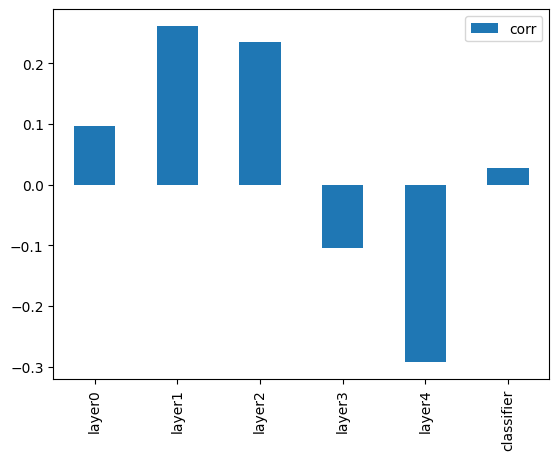

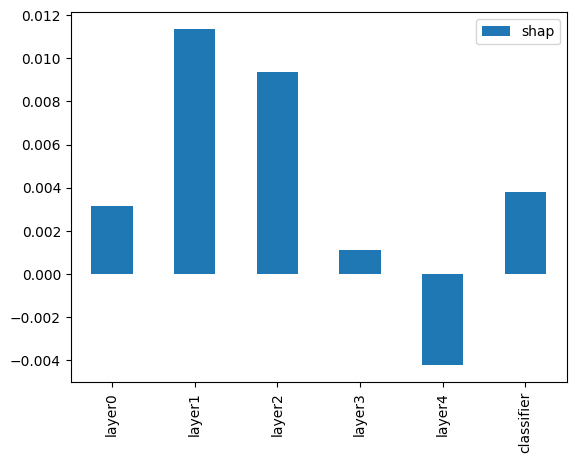

In [ ]:
print(test_env)
df_corr.plot.bar(), df_shap.plot.bar()

In [ ]:
df_shap.loc['layer0'] + df_shap.loc['layer1'] + df_shap.loc['layer2'] + df_shap.loc['layer3']

shap    0.024964
dtype: float64

In [ ]:
df_shap.loc['layer1']

shap    0.011354
Name: layer1, dtype: float64

# Get max weight (softer)

In [ ]:
df_inq = df_man_best[['find_algo', 'count'] + all_box_list + ['tta_acc']]

In [ ]:
df_inq.sample(1)

,find_algo,count,layer0,layer1,layer2,layer3,layer4,classifier,tta_acc
172,layer0_layer1_layer2_classifier,4,True,True,True,False,False,True,0.808635


<Axes: >

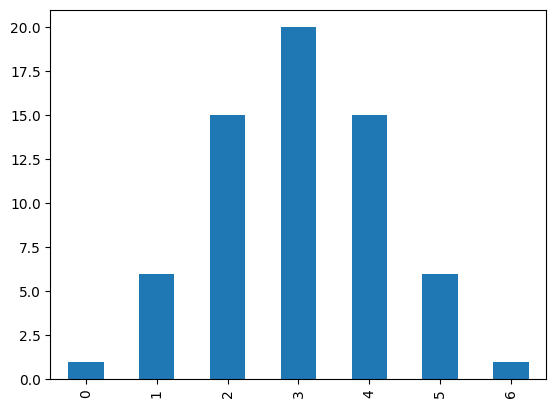

In [ ]:
df_inq['count'].value_counts().sort_index().plot.bar()

In [ ]:
# Group by count and compute min, mean, max
grouped_data = df_inq.groupby('count')['tta_acc'].agg(['min', 'mean', 'max']).reset_index()

####################
# Compute greedy shapley values
full_name = ''
greedy_rank = ['none']
for layer_name in df_shap.sort_values(by='shap', ascending=False).index:
    if full_name != '':
        full_name += '_'
    full_name += layer_name
    greedy_rank.append(full_name)
greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

# Add greedy shapley values to grouped data
grouped_data['shapBinary_GreedyKP'] = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

####################
# Compute greedy correlation values
full_name = ''
greedy_rank = ['none']
for layer_name in df_corr.sort_values(by='corr', ascending=False).index:
    if full_name != '':
        full_name += '_'
    full_name += layer_name
    greedy_rank.append(full_name)
greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

# Add greedy correlation values to grouped data
grouped_data['corrBinary_GreedyKP'] = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

####################
# Compute greedy best single values
full_name = ''
greedy_rank = ['none']
for layer_name in df_inq[df_inq['count'] == 1].sort_values(by='tta_acc', ascending=False)['find_algo'].values:
    if full_name != '':
        full_name += '_'
    full_name += layer_name
    greedy_rank.append(full_name)
greedy_rank = ['_'.join(sorted(sorted(find_algo.split('_')), key=len)) for find_algo in greedy_rank]

# Add greedy best single values to grouped data
grouped_data['singBinary_GreedyKP'] = [df_inq[df_inq['find_algo'] == find_algo]['tta_acc'].values[0] for find_algo in greedy_rank]

In [ ]:
from scipy.optimize import curve_fit

# Define the Gaussian function
def gaussian(x, mu, sigma):
    return 1/(sigma * np.sqrt(2*np.pi)) * np.exp(-(x - mu)**2 / (2*sigma**2))

# Extract the data to be fit
xdata, ydata = grouped_data['count'], grouped_data['max']

# Fit the Gaussian distribution to the dataset
params, cov = curve_fit(gaussian, xdata, ydata)

# Extract the fitted parameters
mu_fit, sigma_fit = params

# Generate the x-axis values for the fitted curve
x = np.linspace(xdata.min(), xdata.max(), 100)
fit_y = gaussian(x, mu_fit, sigma_fit)

In [ ]:
# Fit a 2-degree polynomial
coefficients = np.polyfit(xdata, ydata, 2)
x_curve = np.linspace(x.min(), x.max(), 100)
# Calculate corresponding y-values using the polynomial coefficients
y_curve = np.polyval(coefficients, x_curve)
mu_fit = -coefficients[1] / (2 * coefficients[0])

1


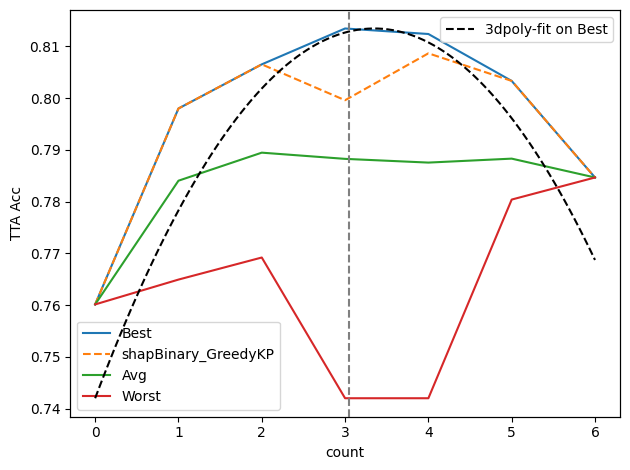

In [ ]:
print(test_env)
# Plot the data and the fitted curve
fig, ax1 = plt.subplots()
ax1.plot(grouped_data['count'], grouped_data['max'], label='Best')
ax1.plot(grouped_data['count'], grouped_data['shapBinary_GreedyKP'], label='shapBinary_GreedyKP', linestyle='--')
# ax1.plot(grouped_data['count'], grouped_data['corrBinary_GreedyKP'], label='corrBinary_GreedyKP')
# ax1.plot(grouped_data['count'], grouped_data['singBinary_GreedyKP'], label='singBinary_GreedyKP')
ax1.plot(grouped_data['count'], grouped_data['mean'], label='Avg')
ax1.plot(grouped_data['count'], grouped_data['min'], label='Worst')
ax1.set_xlabel('count')
ax1.set_ylabel('TTA Acc')
ax1.legend()

# Plot the fitted Gaussian curve
ax2 = ax1.twinx()
# ax2.plot(x, fit_y, c='b', label='gauss-fit on Best', linestyle='--')
ax2.plot(x_curve, y_curve, c='black', label='3dpoly-fit on Best', linestyle='--')
ax2.axvline(mu_fit, color='0.5', linestyle='--')
# ax2.axvline(mu_fit - sigma_fit, color='0.5', linestyle='--')
ax2.set_yticks([])
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_powerset = df_inq['tta_acc'].max()
shapBinaryBest_GreedyKP = grouped_data['shapBinary_GreedyKP'].max()
corrBinaryBest_GreedyKP = grouped_data['corrBinary_GreedyKP'].max()
singBinaryBest_GreedyKP = grouped_data['singBinary_GreedyKP'].max()

max2d_wt = int(mu_fit.round())
shapBinaryMax2d_GreedyKP = grouped_data['shapBinary_GreedyKP'].loc[max2d_wt]
corrBinaryMax2d_GreedyKP = grouped_data['corrBinary_GreedyKP'].loc[max2d_wt]
singBinaryMax2d_GreedyKP = grouped_data['singBinary_GreedyKP'].loc[max2d_wt]
bestBinaryMax2d_GreedyKP = df_inq[df_inq['count'] == max2d_wt]['tta_acc'].max()

(best_powerset), \
(shapBinaryBest_GreedyKP, corrBinaryBest_GreedyKP, singBinaryBest_GreedyKP), \
(shapBinaryMax2d_GreedyKP, corrBinaryMax2d_GreedyKP, singBinaryMax2d_GreedyKP), \
(bestBinaryMax2d_GreedyKP) 

(0.8134328358208951,
 (0.80863539445629, 0.8134328358208951, 0.8065031982942431),
 (0.79957356076759, 0.8134328358208951, 0.7899786780383791),
 0.8134328358208951)

In [ ]:
df_inq[df_inq['count'] == max2d_wt]['tta_acc'].max()

0.8134328358208951

In [ ]:
int(mu_fit.round())

3

# Full results

In [ ]:
# For different datasets and backbones
sweep_start_idx = 0
sweep_end_idx = 1

# For different TTAs
man_start_idx = 0
man_end_idx = 1

# For different envs per dataset and backbone
run_start_idx = 0
run_end_idx = 1

In [ ]:
# Fixed params
full_data_col = 'hp_acc'
low_data_fracs = [0, 0.25, 0.5, 0.75, 1.0]

# For different datasets and backbones
for sweep_name in sweep_names[sweep_start_idx:sweep_end_idx]:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for res_fname, man_fname in zip(res_fnames[man_start_idx:man_end_idx], man_fnames[man_start_idx:man_end_idx]):
        tta_name = man_fname[:-6].split('_')[1]
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs[run_start_idx:run_end_idx]:
            run_dir = os.path.join(sweep_dir, run)

            # Read in results
            df_res = pd.read_json(os.path.join(run_dir, res_fname), lines=True)
            # Get args
            args = df_res['args'][0]
            # Get test env
            test_env = get_test_env(args)
            print('\t\ttest_env: {}'.format(test_env))

            # Read in Man results
            df_man = pd.read_json(os.path.join(run_dir, man_fname), lines=True)

            # Get low data cols
            # low_data_cols = [col for col in df_man.columns.values if 'step' in col]
            low_data_cols = ['hp_acc']
            low_data_fracs = [1.0]

            # For different low data setups
            for target_col, low_data_frac in zip(low_data_cols, low_data_fracs):
                # get best rows for each find_algo column
                print('\t\t\ttarget_col: {}'.format(target_col))
                df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')

                # Compute few stats
                full_box_name = max(df_man_best['find_algo'], key=len)
                all_box_list = full_box_name.split('_')
                single_box_flag = np.array([False]*df_man_best.shape[0])
                for box in all_box_list:
                    single_box_flag = single_box_flag | (df_man_best['find_algo'] == box).values
                    df_man_best[box] = [box in row['find_algo'] for idx, row in df_man_best.iterrows()]

                only_box_list = all_box_list[1:-1]
                train_frac_arr = np.zeros(df_man_best.shape[0])
                for box in only_box_list:
                    train_frac_arr += df_man_best[box].astype(int).values
                df_man_best['train_frac'] = train_frac_arr.astype(int) / 4.0

                # get accs different loc TTA
                dg_acc = df_man_best[df_man_best['find_algo'] == 'none'][target_col].values[0]
                full_acc = df_man_best[df_man_best['find_algo'] == full_box_name][target_col].values[0]
                best_powerset_acc = df_man_best[target_col].values[0]
                worst_powerset_acc = df_man_best[target_col].values[-1]
                best_single_acc = df_man_best[single_box_flag][target_col].values[0]
                df_man_best['loc>full'] = df_man_best[target_col] - full_acc
                df_man_best['subset_quality'] = df_man_best[target_col] - df_man_best[target_col].iloc[-1]

                # Print results
                if True:
                    print("\t\t\t\tBest powerset:\t\t", best_powerset_acc)
                    print("\t\t\t\tWorst powerset:\t\t", worst_powerset_acc)
                    print("\t\t\t\tDG:\t\t\t", dg_acc)
                    print("\t\t\t\tFull TTA:\t\t", full_acc)
                    print('\t\t\t\tBest single block:\t', best_single_acc)

                    print("\t\t\t\t" + "*"*60)
                    print("\t\t\t\tbest powerset > best single: \t", (best_powerset_acc - best_single_acc))
                    print("\t\t\t\tbest powerset > full:\t\t", (best_powerset_acc - full_acc))
                    print("\t\t\t\tbest powerset > dg:\t\t", (best_powerset_acc - dg_acc))
                    print("\t\t\t\tbest powerset > worst powerset:\t", (best_powerset_acc - worst_powerset_acc))
                    print("\t\t\t\t" + "*"*60)

                # Plot results
                if True:
                    # fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(18, 3))
                    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
                    # fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
                    fig.suptitle('{} + {} on {}:env{} at {}%'.format(backbone, tta_name, dataset, test_env, int(low_data_frac*100)))
                    ax_idx = 0

                    axes[ax_idx].axhline(best_powerset_acc, color='m', linestyle='--', label='best powerset')
                    df_man_best[single_box_flag][['find_algo', target_col]].rename(columns={target_col: 'single block', 'find_algo': 'ResNet Block'}).sort_values(by='ResNet Block', ascending=True).set_index('ResNet Block').loc[only_box_list].rename(index={'layer1':'#1', 'layer2':'#2', 'layer3':'#3', 'layer4':'#4'}).plot(ax=axes[ax_idx], kind='line', title='TTA perf', marker="o", color='b')
                    axes[ax_idx].axhline(full_acc, color='r', linestyle='--', label='full')
                    axes[ax_idx].axhline(dg_acc, color='0.4', linestyle='--', label='dg')
                    axes[ax_idx].set_ylabel('Accuracy')
                    axes[ax_idx].legend(fontsize=10)
                    ax_idx += 1
                    
                    df_man_best[only_box_list + [target_col]].corr()[target_col].drop(target_col).rename(index={'layer1':'#1', 'layer2':'#2', 'layer3':'#3', 'layer4':'#4'}).plot.line(ax=axes[ax_idx], title='Block selection correlation plot', marker="o", color='g', label='Corr(Block participation, TTA perf)')
                    axes[ax_idx].axhline(0, color='black', linestyle='--')
                    axes[ax_idx].set_ylim(-1, 1)
                    axes[ax_idx].set_ylabel('Correlation')
                    axes[ax_idx].set_xlabel('ResNet Block')
                    axes[ax_idx].legend(fontsize=10)
                    ax_idx += 1

                    df_man_best[['train_frac'] + [target_col]].rename(columns={'train_frac': '#blocks'}).corr()[target_col].drop(target_col).plot(ax=axes[ax_idx], kind='bar', title=f'No. of trainable blocks correlation plot', color='g', label='Corr(No. of trainable blocks, TTA perf)')
                    axes[ax_idx].axhline(0, color='black', linestyle='--')
                    axes[ax_idx].set_ylim(-1, 1)
                    axes[ax_idx].set_ylabel('Correlation')
                    axes[ax_idx].legend(fontsize=10)
                    # df_man_best[['train_frac', 'subset_quality'] + [target_col]].corr()[target_col].drop(target_col).plot.bar(ax=axes[ax_idx], title=f'Corr: All metrics vs {target_col}')
                    ax_idx += 1
                    
                    plt.tight_layout()
                    plt.show()

                # Plot results
                if True:
                    # x_axis = np.array(list(range(df_man_best.shape[0])))
                    plt.figure(figsize=(15, 5))
                    plt.axhline(best_powerset_acc, color='m', linestyle='--', label='best powerset')
                    plt.axhline(best_single_acc, color='b', linestyle='--', label='best single block')
                    plt.plot(df_man_best['find_algo'], df_man_best[target_col], label='subset', marker="o", color='tab:brown')
                    plt.axhline(full_acc, color='r', linestyle='--', label='full')
                    plt.axhline(dg_acc, color='0.4', linestyle='--', label='dg')
                    plt.xticks(rotation=90)
                    plt.title('Powerset results plot ({} + {} on {}:env{} at {}%)'.format(backbone, tta_name, dataset, test_env, int(low_data_frac*100)))
                    plt.ylabel('Accuracy')
                    plt.xlabel('Subset')
                    plt.legend()
                    plt.show()
                # assert False

            # break
        # break
    # break

            # # get best rows for each find_algo column
            # for 
            # df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')

# Low data results

In [ ]:
# For different datasets and backbones
sweep_start_idx = 0
sweep_end_idx = 1

# For different TTAs
man_start_idx = 0
man_end_idx = 1

# For different envs per dataset and backbone
run_start_idx = 0
run_end_idx = 1


In [ ]:
# Fixed params
full_data_col = 'hp_acc'
low_data_fracs = [0, 0.25, 0.5, 0.75, 1.0]

# For different datasets and backbones
for sweep_name in sweep_names[sweep_start_idx:sweep_end_idx]:
    dataset, backbone, dg, mark = sweep_name.split('_')
    print('dataset: {}, backbone: {}'.format(dataset, backbone))

    # Get sweep dir
    sweep_dir = os.path.join(input_dir, sweep_name)

    # Get runs
    runs = [run for run in sorted(os.listdir(sweep_dir))
                                        if os.path.isdir(os.path.join(sweep_dir, run))]

    # For different TTAs
    for res_fname, man_fname in zip(res_fnames[man_start_idx:man_end_idx], man_fnames[man_start_idx:man_end_idx]):
        tta_name = man_fname[:-6].split('_')[1]
        print('\ttta: {}'.format(tta_name))

        # For different envs per dataset and backbone
        for run in runs[run_start_idx:run_end_idx]:
            run_dir = os.path.join(sweep_dir, run)

            # Read in results
            df_res = pd.read_json(os.path.join(run_dir, res_fname), lines=True)
            # Get args
            args = df_res['args'][0]
            # Get test env
            test_env = get_test_env(args)
            print('\t\ttest_env: {}'.format(test_env))

            # Read in Man results
            df_man = pd.read_json(os.path.join(run_dir, man_fname), lines=True)

            # Get low data cols
            low_data_cols = [col for col in df_man.columns.values if 'step' in col]
            # low_data_cols = ['hp_acc']
            # low_data_fracs = [1.0]

            # For different low data setups
            for target_col, low_data_frac in zip(low_data_cols, low_data_fracs):
                if low_data_frac == 0:
                    continue
                # get best rows for each find_algo column
                print('\t\t\ttarget_col: {}'.format(target_col))
                df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')

                # Compute few stats
                full_box_name = max(df_man_best['find_algo'], key=len)
                all_box_list = full_box_name.split('_')
                single_box_flag = np.array([False]*df_man_best.shape[0])
                for box in all_box_list:
                    single_box_flag = single_box_flag | (df_man_best['find_algo'] == box).values
                    df_man_best[box] = [box in row['find_algo'] for idx, row in df_man_best.iterrows()]

                only_box_list = all_box_list[1:-1]
                train_frac_arr = np.zeros(df_man_best.shape[0])
                for box in only_box_list:
                    train_frac_arr += df_man_best[box].astype(int).values
                df_man_best['train_frac'] = train_frac_arr.astype(int) / 4.0

                # get accs different loc TTA
                dg_acc = df_man_best[df_man_best['find_algo'] == 'none'][target_col].values[0]
                full_acc = df_man_best[df_man_best['find_algo'] == full_box_name][target_col].values[0]
                best_powerset_acc = df_man_best[target_col].values[0]
                worst_powerset_acc = df_man_best[target_col].values[-1]
                best_single_acc = df_man_best[single_box_flag][target_col].values[0]
                df_man_best['loc>full'] = df_man_best[target_col] - full_acc
                df_man_best['subset_quality'] = df_man_best[target_col] - df_man_best[target_col].iloc[-1]

                # Print results
                # Plot results
                if True:
                    # fig, axes = plt.subplots(nrows=1, ncols=6, figsize=(18, 3))
                    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
                    # fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
                    fig.suptitle('{} + {} on {}:env{} at {}%'.format(backbone, tta_name, dataset, test_env, int(low_data_frac*100)))
                    ax_idx = 0

                    axes[ax_idx].axhline(best_powerset_acc, color='m', linestyle='--', label='best powerset')
                    df_man_best[single_box_flag][['find_algo', target_col]].rename(columns={'find_algo': 'ResNet Block'}).sort_values(by='ResNet Block', ascending=True).set_index('ResNet Block').loc[only_box_list].rename(index={'layer1':'#1', 'layer2':'#2', 'layer3':'#3', 'layer4':'#4'}).plot(ax=axes[ax_idx], kind='line', title='TTA perf', marker="o", color='b')
                    axes[ax_idx].axhline(full_acc, color='r', linestyle='--', label='full')
                    axes[ax_idx].axhline(dg_acc, color='0.4', linestyle='--', label='dg')
                    axes[ax_idx].set_ylabel('Accuracy')
                    axes[ax_idx].legend(fontsize=10)
                    ax_idx += 1
                    
                    df_man_best[only_box_list + [target_col]].corr()[target_col].drop(target_col).rename(index={'layer1':'#1', 'layer2':'#2', 'layer3':'#3', 'layer4':'#4'}).plot.line(ax=axes[ax_idx], title='Block selection correlation plot', marker="o", color='g', label='Corr(Block participation, TTA perf)')
                    axes[ax_idx].axhline(0, color='black', linestyle='--')
                    axes[ax_idx].set_ylim(-1, 1)
                    axes[ax_idx].set_ylabel('Correlation')
                    axes[ax_idx].set_xlabel('ResNet Block')
                    axes[ax_idx].legend(fontsize=10)
                    ax_idx += 1

                    df_man_best[['train_frac'] + [target_col]].rename(columns={'train_frac': '#blocks'}).corr()[target_col].drop(target_col).plot(ax=axes[ax_idx], kind='bar', title=f'No. of trainable blocks correlation plot', color='g', label='Corr(No. of trainable blocks, TTA perf)')
                    axes[ax_idx].axhline(0, color='black', linestyle='--')
                    axes[ax_idx].set_ylim(-1, 1)
                    axes[ax_idx].set_ylabel('Correlation')
                    axes[ax_idx].legend(fontsize=10)
                    # df_man_best[['train_frac', 'subset_quality'] + [target_col]].corr()[target_col].drop(target_col).plot.bar(ax=axes[ax_idx], title=f'Corr: All metrics vs {target_col}')
                    ax_idx += 1
                    
                    plt.tight_layout()
                    plt.show()

                # Plot results
                if False:
                    # x_axis = np.array(list(range(df_man_best.shape[0])))
                    plt.figure(figsize=(15, 5))
                    plt.axhline(best_powerset_acc, color='m', linestyle='--', label='best powerset')
                    plt.axhline(best_single_acc, color='b', linestyle='--', label='best single block')
                    plt.plot(df_man_best['find_algo'], df_man_best[target_col], label='subset', marker="o", color='tab:brown')
                    plt.axhline(full_acc, color='r', linestyle='--', label='full')
                    plt.axhline(dg_acc, color='0.4', linestyle='--', label='dg')
                    plt.xticks(rotation=90)
                    plt.title('Powerset results plot ({} + {} on {}:env{} at {}%)'.format(backbone, tta_name, dataset, test_env, int(low_data_frac*100)))
                    plt.ylabel('Accuracy')
                    plt.xlabel('Subset')
                    plt.legend()
                    plt.show()
                # assert False

            # break
        # break
    # break

            # # get best rows for each find_algo column
            # for 
            # df_man_best = df_man.sort_values(by=[target_col], ascending=False).drop_duplicates(subset='find_algo', keep='first')